## Tumor mutational burden by cancer type

Uses analysis `log_mut` = log$_{10}$(mutation count + 1). Dashed line = clinical high TMB (10 mut/Mb × 30 Mb WES = 300 mutations).


In [3]:
import socket, os, sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

mpl.rcParams["pdf.fonttype"] = 42

hostname = socket.gethostname()
if "scg" in hostname:
    BASE_DIR = "/labs/mwinslow/Karen/protein-master/v2_pancan_batch_corrected"
else:
    BASE_DIR = os.path.expanduser("~/Documents/research/scg/protein-master/v2_pancan_batch_corrected")

DATA_DIR = f"{BASE_DIR}/data/tcga_xena"
FIG_DIR = f"{BASE_DIR}/local/figures"
PCA_OUT_DIR = f"{BASE_DIR}/results/figures/main/fig_pca"
os.makedirs(PCA_OUT_DIR, exist_ok=True)
BETA_PATH = f"{BASE_DIR}/analysis/00_reproduction/tilk_et_al_2023/gene_sets/bh/tcga_all_genes_beta.tsv"
PQC_PATH = f"{BASE_DIR}/data/corum/pqc_annotation.tsv"
os.chdir(DATA_DIR)

sys.path.insert(0, FIG_DIR)
from palette import COLORS

color_df = pd.read_csv(f"{FIG_DIR}/tcga_hex_color_codes.csv")
TCGA_COLORS = dict(zip(color_df["cancer_type"], color_df["cancer_type_color"]))

PQC_COLOR = COLORS["high"]
NON_PQC_COLOR = COLORS["ns"]
FDR_THRESH = 0.05

In [4]:
expr = pd.read_csv(f"{DATA_DIR}/data_ready/tcga_regression_ready_imputed.csv")

meta_cols = ["cancer_type", "barcode", "log_mut", "purity"]
gene_cols = [c for c in expr.columns if c not in meta_cols]

sample_counts = (
    expr.groupby("cancer_type")["barcode"]
    .count()
    .sort_values(ascending=False)
    .rename("n_samples")
    .to_frame()
)
sample_counts["pct"] = sample_counts["n_samples"] / sample_counts["n_samples"].sum() * 100

print(f"Total samples: {sample_counts['n_samples'].sum():,}")
print(f"Genes in PCA: {len(gene_cols):,}")
sample_counts

Total samples: 9,104
Genes in PCA: 19,599


,n_samples,pct
cancer_type,,
BRCA,1018,11.181898
UCEC,516,5.667838
LGG,512,5.623902
LUAD,511,5.612917
HNSC,499,5.481107
PRAD,496,5.448155
THCA,490,5.382250
LUSC,483,5.305360
STAD,412,4.525483


## Pie chart


In [ ]:
name_lookup = pd.read_csv(
    f"{DATA_DIR}/intermediate/tcga_cancer_type_lookup_harmonized.csv"
).set_index("abbreviation")["study_name"]

labels = sample_counts.index.tolist()
sizes = sample_counts["n_samples"].tolist()
pie_colors = [TCGA_COLORS.get(ct, COLORS["light_gray"]) for ct in labels]
legend_labels = [
    f"{ct} — {name_lookup.get(ct, ct)} (n={n:,}, {pct:.1f}%)"
    for ct, n, pct in zip(labels, sizes, sample_counts["pct"])
]

fig, ax = plt.subplots(figsize=(8, 8))
wedges, _ = ax.pie(
    sizes,
    colors=pie_colors,
    startangle=90,
    counterclock=False,
    wedgeprops={"linewidth": 0.5, "edgecolor": "white"},
)

# Label only the top 5 cancer types on the pie
for wedge, label in zip(wedges[:5], labels[:5]):
    ang = np.deg2rad((wedge.theta2 + wedge.theta1) / 2.0)
    x, y = 0.65 * np.cos(ang), 0.65 * np.sin(ang)
    ax.text(
        x, y, label,
        ha="center", va="center",
        fontsize=8, fontweight="bold", color=COLORS["dark_gray"],
    )

ax.legend(
    wedges,
    legend_labels,
    title="Cancer type",
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),
    frameon=False,
    fontsize=8,
)
n_samples_total = int(sample_counts["n_samples"].sum())
ax.set_title(
    f"TCGA sample composition by cancer type\nTotal samples: {n_samples_total:,}",
    fontsize=12,
)
ax.set_aspect("equal")
plt.tight_layout()
plt.show()


## Tumor purity by cancer type

Horizontal boxplots from `data_ready/barcode_purity.csv`, ordered by median purity.


In [ ]:
meta = pd.read_csv(f"{DATA_DIR}/data_ready/barcode_purity.csv")

order = (
    meta.groupby("cancer_type")["purity"]
    .median()
    .sort_values()
    .index.tolist()
)
data = [meta.loc[meta["cancer_type"] == ct, "purity"].values for ct in order]
colors = [TCGA_COLORS.get(ct, COLORS["light_gray"]) for ct in order]
ylabels = [
    f"{ct} (n={int((meta['cancer_type'] == ct).sum())})"
    for ct in order
]

fig, ax = plt.subplots(figsize=(7, 9))
bp = ax.boxplot(
    data,
    vert=False,
    patch_artist=True,
    widths=0.65,
    showfliers=False,
    medianprops={"color": COLORS["dark_gray"], "linewidth": 1.2},
    whiskerprops={"color": "#666666", "linewidth": 0.8},
    capprops={"color": "#666666", "linewidth": 0.8},
    boxprops={"linewidth": 0.6, "edgecolor": "white"},
)
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.9)

ax.set_yticklabels(ylabels, fontsize=8)
ax.set_xlabel("Tumor purity", fontsize=11)
ax.set_xlim(0, 1.02)
ax.axvline(0.5, color=COLORS["light_gray"], linewidth=0.8, linestyle="--", zorder=0)
ax.set_title(
    "TCGA tumor purity by cancer type\n(ordered by median; outliers hidden)",
    fontsize=12,
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


## Tumor mutational burden by cancer type

Uses analysis `log_mut` = log$_{10}$(mutation count + 1). Dashed line = clinical high TMB (10 mut/Mb × 30 Mb WES = 300 mutations).


In [ ]:
meta = pd.read_csv(f"{DATA_DIR}/data_ready/barcode_purity.csv")
tmb = pd.read_csv(f"{DATA_DIR}/processed/tcga_tmb_summary.csv")
df_tmb = meta.merge(tmb[["barcode", "log_mut", "num_mut"]], on="barcode", how="inner")

# Match 05_calculate_tmb.py: TMB = num_mut / 30 Mb; log_mut = log10(num_mut + 1)
WES_MB = 30
HIGH_TMB_PER_MB = 10  # FDA clinical cutoff (mut/Mb)
HIGH_MUT_COUNT = HIGH_TMB_PER_MB * WES_MB  # 300 mutations
HIGH_LOG = np.log10(HIGH_MUT_COUNT + 1)

order = (
    df_tmb.groupby("cancer_type")["log_mut"]
    .median()
    .sort_values()
    .index.tolist()
)
data = [df_tmb.loc[df_tmb["cancer_type"] == ct, "log_mut"].values for ct in order]
colors = [TCGA_COLORS.get(ct, COLORS["light_gray"]) for ct in order]
ylabels = [
    f"{ct} (n={int((df_tmb['cancer_type'] == ct).sum())})"
    for ct in order
]
ypos = np.arange(1, len(order) + 1)
rng = np.random.default_rng(0)

fig, ax = plt.subplots(figsize=(7, 9))

for y, vals, c in zip(ypos, data, colors):
    jitter = rng.uniform(-0.22, 0.22, size=len(vals))
    ax.scatter(
        vals, y + jitter,
        s=6, c=c, alpha=0.35, linewidths=0, zorder=1, rasterized=True,
    )

bp = ax.boxplot(
    data,
    vert=False,
    patch_artist=True,
    widths=0.65,
    showfliers=False,
    medianprops={"color": COLORS["dark_gray"], "linewidth": 1.2},
    whiskerprops={"color": "#666666", "linewidth": 0.8},
    capprops={"color": "#666666", "linewidth": 0.8},
    boxprops={"linewidth": 0.8, "edgecolor": COLORS["dark_gray"]},
    zorder=3,
)
for patch, c in zip(bp["boxes"], colors):
    patch.set_facecolor(c)
    patch.set_alpha(0.25)

ax.axvline(
    HIGH_LOG, color=COLORS["sig_strong"], linewidth=1.2, linestyle="--", zorder=4,
    label=fr"High TMB (≥{HIGH_TMB_PER_MB:g} mut/Mb ≈ {HIGH_MUT_COUNT:g} mut)",
)
ax.legend(frameon=False, loc="lower right", fontsize=9)

ax.set_yticks(ypos)
ax.set_yticklabels(ylabels, fontsize=8)
ax.set_xlabel(r"log$_{10}$(mutation count + 1)", fontsize=11)
ax.set_title(
    "TCGA tumor mutational burden by cancer type\n(ordered by median; each point = one sample)",
    fontsize=12,
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
plt.tight_layout()
plt.show()


## PCA

In [6]:
X_scaled = StandardScaler().fit_transform(expr[gene_cols])
pca = PCA(n_components=2)
pcs = pca.fit_transform(X_scaled)
var = pca.explained_variance_ratio_

type_map = color_df[["cancer_type", "organ_system", "organ_system_color"]].drop_duplicates("cancer_type")
expr = expr.drop(columns=[c for c in ["organ_system", "organ_system_color"] if c in expr.columns])
expr = expr.merge(type_map, on="cancer_type", how="left")
ORGAN_COLORS = (
    color_df[["organ_system", "organ_system_color"]]
    .drop_duplicates("organ_system")
    .set_index("organ_system")["organ_system_color"]
    .to_dict()
)
all_cancer_types = sorted(expr["cancer_type"].unique())
organ_systems = sorted(expr["organ_system"].dropna().unique())

LOG_MUT_VMIN = float(np.percentile(expr["log_mut"], 5))
LOG_MUT_VMAX = float(np.percentile(expr["log_mut"], 95))
log_mut_norm = mpl.colors.Normalize(vmin=LOG_MUT_VMIN, vmax=LOG_MUT_VMAX)

print(f"PC1 variance explained: {var[0]:.1%}")
print(f"PC2 variance explained: {var[1]:.1%}")
print(f"Organ systems in data: {len(organ_systems)}")
print(f"log_mut color scale: {LOG_MUT_VMIN:.2f} to {LOG_MUT_VMAX:.2f} (5th-95th pct; higher values saturate)")


PC1 variance explained: 10.5%
PC2 variance explained: 9.2%
Organ systems in data: 13
log_mut color scale: 1.08 to 2.90 (5th-95th pct; higher values saturate)


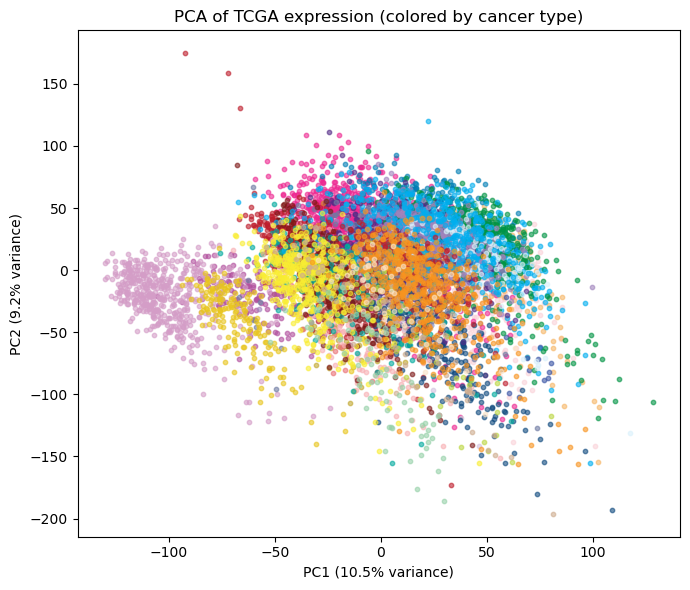

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))

for ct in all_cancer_types:
    idx = expr["cancer_type"] == ct
    ax.scatter(
        pcs[idx, 0],
        pcs[idx, 1],
        s=10,
        alpha=0.6,
        color=TCGA_COLORS.get(ct, COLORS["light_gray"]),
        rasterized=True,
    )

ax.set_xlabel(f"PC1 ({var[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1%} variance)")
ax.set_title("PCA of TCGA expression (colored by cancer type)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{PCA_OUT_DIR}/pca_cancer_type.pdf", dpi=300, bbox_inches="tight")
plt.show()


## PCA colored by log(TMB)


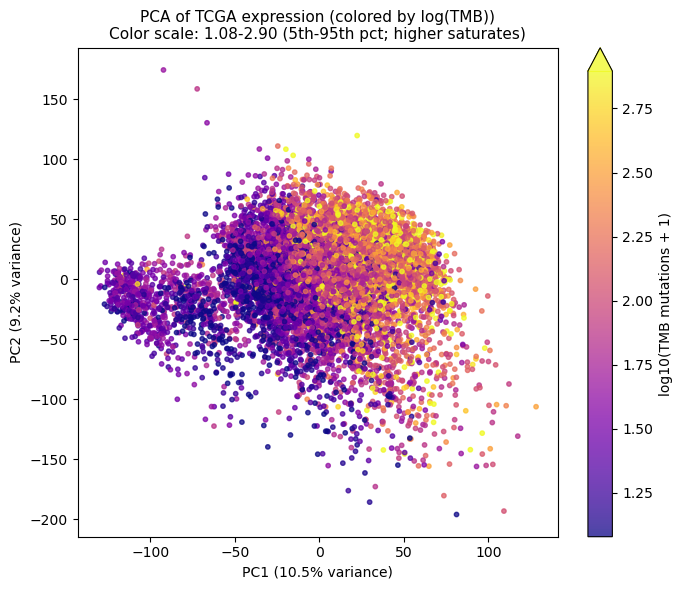

In [8]:
fig, ax = plt.subplots(figsize=(7, 6))

sc = ax.scatter(
    pcs[:, 0],
    pcs[:, 1],
    c=expr["log_mut"],
    cmap="plasma",
    norm=log_mut_norm,
    s=10,
    alpha=0.75,
    rasterized=True,
)

ax.set_xlabel(f"PC1 ({var[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1%} variance)")
ax.set_title(
    "PCA of TCGA expression (colored by log(TMB))\n"
    f"Color scale: {LOG_MUT_VMIN:.2f}-{LOG_MUT_VMAX:.2f} (5th-95th pct; higher saturates)",
    fontsize=11,
)
cbar = plt.colorbar(sc, ax=ax, extend="max")
cbar.set_label("log10(TMB mutations + 1)")
plt.tight_layout()
plt.savefig(f"{PCA_OUT_DIR}/pca_log_mut.pdf", dpi=300, bbox_inches="tight")
plt.show()


## PCA colored by organ system


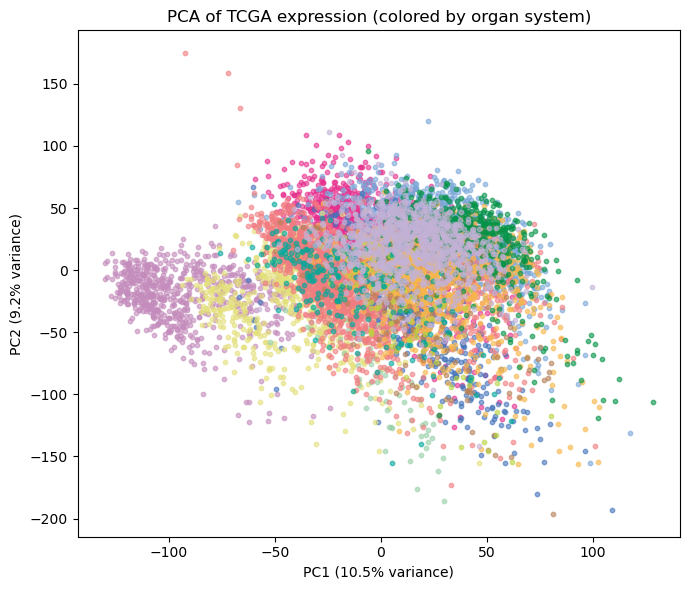

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))

for organ in organ_systems:
    idx = expr["organ_system"] == organ
    ax.scatter(
        pcs[idx, 0],
        pcs[idx, 1],
        s=10,
        alpha=0.6,
        color=ORGAN_COLORS.get(organ, COLORS["light_gray"]),
        rasterized=True,
    )

ax.set_xlabel(f"PC1 ({var[0]:.1%} variance)")
ax.set_ylabel(f"PC2 ({var[1]:.1%} variance)")
ax.set_title("PCA of TCGA expression (colored by organ system)", fontsize=12)
plt.tight_layout()
plt.savefig(f"{PCA_OUT_DIR}/pca_organ_system.pdf", dpi=300, bbox_inches="tight")
plt.show()


## PCA legends


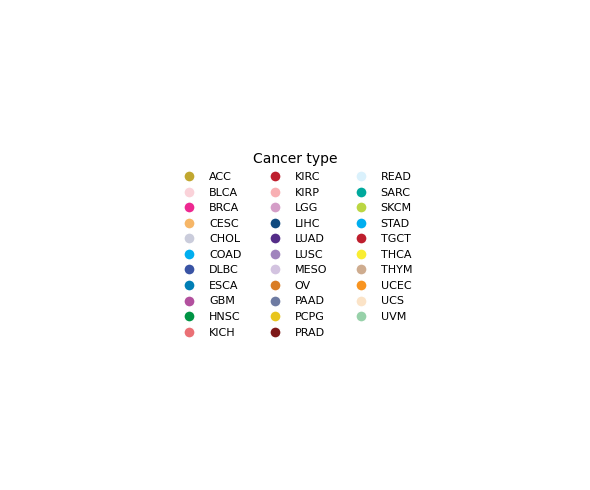

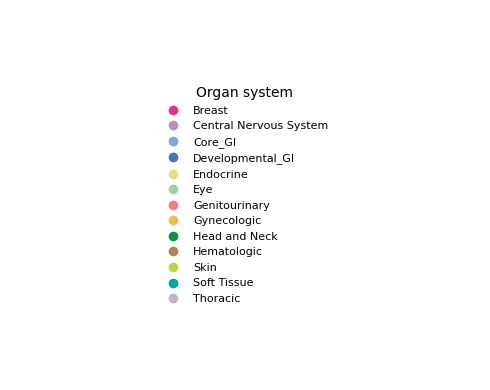

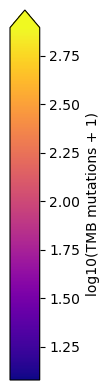

In [10]:
cancer_handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=TCGA_COLORS.get(ct, COLORS["light_gray"]),
        markersize=8,
        label=ct,
    )
    for ct in all_cancer_types
]

fig, ax = plt.subplots(figsize=(6, 5))
ax.axis("off")
ax.legend(handles=cancer_handles, loc="center", frameon=False, ncol=3, fontsize=8, title="Cancer type")
plt.tight_layout()
plt.savefig(f"{PCA_OUT_DIR}/pca_legend_cancer_type.pdf", dpi=300, bbox_inches="tight")
plt.show()

organ_handles = [
    plt.Line2D(
        [0], [0],
        marker="o",
        color="w",
        markerfacecolor=ORGAN_COLORS.get(org, COLORS["light_gray"]),
        markersize=8,
        label=org,
    )
    for org in organ_systems
]

fig, ax = plt.subplots(figsize=(5, 4))
ax.axis("off")
ax.legend(handles=organ_handles, loc="center", frameon=False, fontsize=8, title="Organ system")
plt.tight_layout()
plt.savefig(f"{PCA_OUT_DIR}/pca_legend_organ_system.pdf", dpi=300, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(1.2, 4))
cb = mpl.colorbar.ColorbarBase(ax, cmap="plasma", norm=log_mut_norm, orientation="vertical", extend="max")
cb.set_label("log10(TMB mutations + 1)")
plt.tight_layout()
plt.savefig(f"{PCA_OUT_DIR}/pca_legend_log_mut.pdf", dpi=300, bbox_inches="tight")
plt.show()


## TMB association gene landscape (PQC vs. non-PQC)

In [11]:
beta = pd.read_csv(BETA_PATH, sep="\t")

pqc_genes = pd.read_csv(PQC_PATH, sep="\t")
pqc_genes.loc[pqc_genes["Hugo"] == "TOR4A", "Hugo"] = "C9orf167"
pqc_genes.loc[pqc_genes["Hugo"] == "FAXC", "Hugo"] = "C6orf168"
pqc_set = set(pqc_genes["Hugo"].unique())

beta = beta.copy()
beta["is_pqc"] = beta["gene"].isin(pqc_set)
beta["neglog10_fdr"] = -np.log10(beta["fdr_bh"].clip(lower=1e-300))
beta["sig"] = beta["fdr_bh"] < FDR_THRESH
beta = beta.sort_values("estimate").reset_index(drop=True)
beta["rank"] = np.arange(1, len(beta) + 1)

# Non-PQC pathways from fig1d (KEGG ORA on TMB-up non-PQC genes)
KEGG_PATH = f"{BASE_DIR}/analysis/04_enrichment/ora/kegg_ora_tmb_up_non_pqc.csv"
kegg = pd.read_csv(KEGG_PATH)

PATHWAY_META = {
    "ribosome_biogenesis_in_eukaryotes": "Ribosome biogenesis",
    "spliceosome": "Spliceosome",
    "dna_replication": "DNA replication",
    "cell_cycle": "Cell cycle",
    "oxidative_phosphorylation": "Oxidative phosphorylation",
    "antigen_processing_and_presentation": "Antigen processing",
}
PATHWAY_KEGG_DESC = {
    "ribosome_biogenesis_in_eukaryotes": "Ribosome biogenesis in eukaryotes",
    "spliceosome": "Spliceosome",
    "dna_replication": "DNA replication",
    "cell_cycle": "Cell cycle",
    "oxidative_phosphorylation": "Oxidative phosphorylation",
    "antigen_processing_and_presentation": "Antigen processing and presentation",
}
PATHWAY_COLORS = {
    "ribosome_biogenesis_in_eukaryotes": COLORS["accent1"],
    "spliceosome": COLORS["accent2"],
    "dna_replication": COLORS["accent3"],
    "cell_cycle": COLORS["accent5"],
    "oxidative_phosphorylation": COLORS["accent4"],
    "antigen_processing_and_presentation": COLORS["low"],
}

PATHWAY_GENES = {}
for pathway, desc in PATHWAY_KEGG_DESC.items():
    row = kegg[kegg["Description"] == desc]
    genes = row.iloc[0]["geneID"].split("/") if len(row) else []
    PATHWAY_GENES[pathway] = set(genes)

gene_to_pathway = {}
for pathway, genes in PATHWAY_GENES.items():
    for gene in genes:
        if gene not in gene_to_pathway:
            gene_to_pathway[gene] = pathway
beta["pathway"] = beta["gene"].map(gene_to_pathway)

# Representative labels: top 5 significant PQC genes by beta
PQC_ANNOT_GENES = (
    beta.loc[beta["is_pqc"] & beta["sig"]]
    .sort_values("estimate", ascending=False)
    .head(5)["gene"]
    .tolist()
)

# One representative non-PQC gene per fig1 pathway (top significant beta)
NON_PQC_ANNOT = {}
for pathway, genes in PATHWAY_GENES.items():
    sub = beta.loc[~beta["is_pqc"] & beta["gene"].isin(genes) & beta["sig"]].sort_values(
        "estimate", ascending=False
    )
    if len(sub):
        NON_PQC_ANNOT[pathway] = sub.iloc[0]["gene"]

print(f"Total genes: {len(beta):,}")
print(f"PQC genes: {beta['is_pqc'].sum():,}")
print(f"PQC genes FDR < {FDR_THRESH}: {(beta['is_pqc'] & beta['sig']).sum():,}")
print("PQC labels:", PQC_ANNOT_GENES)
print("Non-PQC pathway labels:", {PATHWAY_META[k]: v for k, v in NON_PQC_ANNOT.items()})
beta.loc[beta["is_pqc"], ["gene", "estimate", "fdr_bh"]].sort_values("estimate", ascending=False).head(10)

Total genes: 16,341
PQC genes: 257
PQC genes FDR < 0.05: 177
PQC labels: ['PSMD12', 'PSMD14', 'HSPD1', 'CCT5', 'PSMD11']
Non-PQC pathway labels: {'Ribosome biogenesis': 'RBM28', 'Spliceosome': 'SNRPA1', 'DNA replication': 'FEN1', 'Cell cycle': 'CHEK1', 'Oxidative phosphorylation': 'UQCRHL', 'Antigen processing': 'IFNG'}


,gene,estimate,fdr_bh
16278,PSMD12,0.322228,2.037089e-56
16244,PSMD14,0.312835,3.325177e-49
16187,HSPD1,0.299497,1.524204e-49
16162,CCT5,0.293624,4.787339e-50
16128,PSMD11,0.284830,3.912012e-46
16096,MRPL19,0.276296,5.377895e-34
16079,PSMA6,0.272606,7.275799e-35
16019,PSMC2,0.258666,6.698337e-31
16017,PSMB2,0.258035,5.896017e-34
16014,CCT6A,0.257830,4.518432e-32


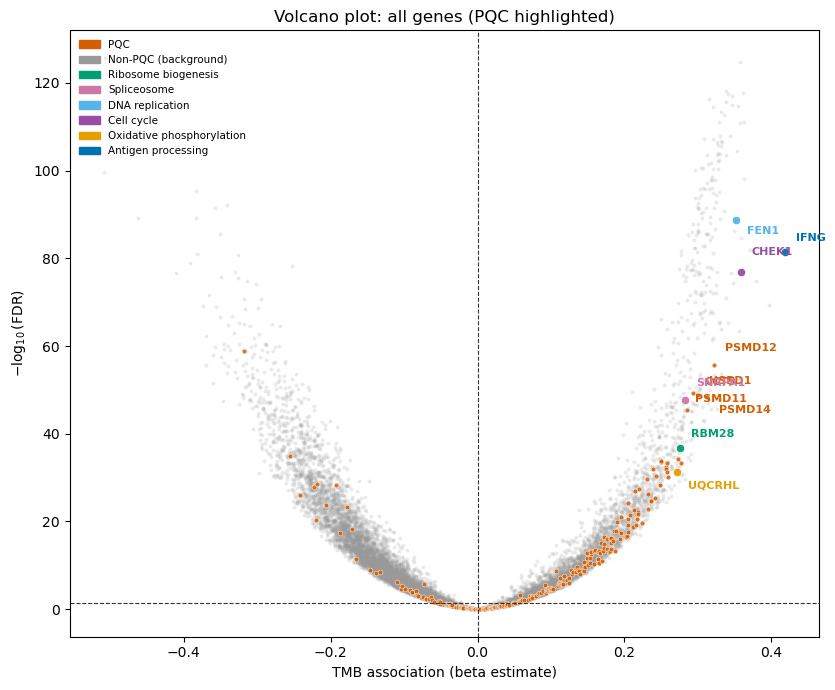

In [12]:
import matplotlib.patches as mpatches

non_pqc = beta[~beta["is_pqc"]]
pqc = beta[beta["is_pqc"]]
non_pqc_bg = non_pqc[~non_pqc["gene"].isin(NON_PQC_ANNOT.values())]

fig, ax = plt.subplots(figsize=(8.5, 7))

ax.scatter(
    non_pqc_bg["estimate"],
    non_pqc_bg["neglog10_fdr"],
    s=8,
    alpha=0.2,
    color=NON_PQC_COLOR,
    linewidths=0,
    rasterized=True,
    zorder=1,
)
ax.scatter(
    pqc["estimate"],
    pqc["neglog10_fdr"],
    s=12,
    alpha=0.85,
    color=PQC_COLOR,
    edgecolors="white",
    linewidths=0.4,
    rasterized=True,
    zorder=2,
)

for pathway, gene in NON_PQC_ANNOT.items():
    row = beta.loc[beta["gene"] == gene].iloc[0]
    ax.scatter(
        row["estimate"],
        row["neglog10_fdr"],
        s=36,
        alpha=0.95,
        color=PATHWAY_COLORS[pathway],
        edgecolors="white",
        linewidths=0.5,
        zorder=4,
    )

PQC_LABEL_OFFSETS = {
    "PSMD12": (8, 10),
    "PSMD14": (8, -12),
    "HSPD1": (8, 8),
    "CCT5": (8, 6),
    "PSMC2": (8, -10),
}
PATHWAY_LABEL_OFFSETS = {
    "ribosome_biogenesis_in_eukaryotes": (8, 8),
    "spliceosome": (8, 10),
    "dna_replication": (8, -10),
    "cell_cycle": (8, 12),
    "oxidative_phosphorylation": (8, -12),
    "antigen_processing_and_presentation": (8, 8),
}

for gene in PQC_ANNOT_GENES:
    row = beta.loc[beta["gene"] == gene].iloc[0]
    dx, dy = PQC_LABEL_OFFSETS.get(gene, (6, 6))
    ax.annotate(
        gene,
        (row["estimate"], row["neglog10_fdr"]),
        textcoords="offset points",
        xytext=(dx, dy),
        fontsize=8,
        color=PQC_COLOR,
        fontweight="bold",
        ha="left",
        zorder=6,
    )

for pathway, gene in NON_PQC_ANNOT.items():
    row = beta.loc[beta["gene"] == gene].iloc[0]
    dx, dy = PATHWAY_LABEL_OFFSETS.get(pathway, (6, 6))
    ax.annotate(
        gene,
        (row["estimate"], row["neglog10_fdr"]),
        textcoords="offset points",
        xytext=(dx, dy),
        fontsize=8,
        color=PATHWAY_COLORS[pathway],
        fontweight="bold",
        ha="left",
        zorder=6,
    )

ax.axvline(0, color=COLORS["dark_gray"], lw=0.8, ls="--")
ax.axhline(-np.log10(FDR_THRESH), color=COLORS["dark_gray"], lw=0.8, ls="--")
ax.set_xlabel("TMB association (beta estimate)")
ax.set_ylabel(r"$-\log_{10}$(FDR)")
ax.set_title("Volcano plot: all genes (PQC highlighted)", fontsize=12)

legend_handles = [
    mpatches.Patch(color=PQC_COLOR, label="PQC"),
    mpatches.Patch(color=NON_PQC_COLOR, label="Non-PQC (background)"),
]
for pathway in PATHWAY_META:
    if pathway in NON_PQC_ANNOT:
        legend_handles.append(
            mpatches.Patch(color=PATHWAY_COLORS[pathway], label=PATHWAY_META[pathway])
        )
ax.legend(handles=legend_handles, frameon=False, loc="upper left", fontsize=7.5)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/tcga_all_genes_volcano_pqc.pdf", dpi=300, bbox_inches="tight")
plt.show()

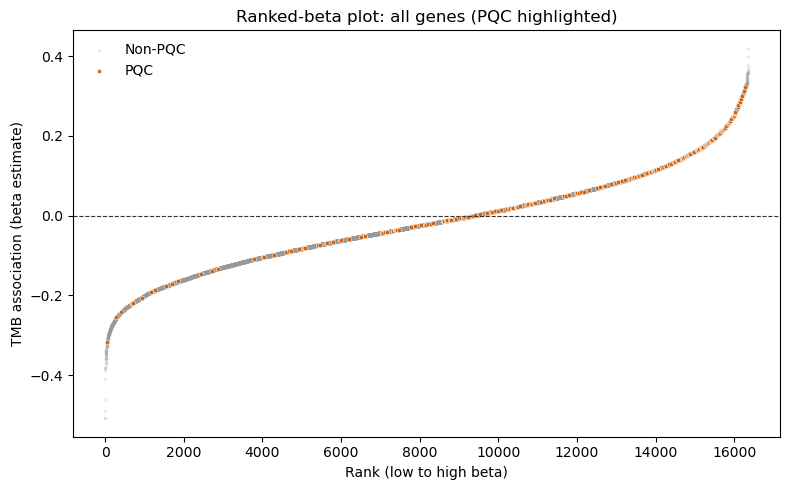

In [13]:
fig, ax = plt.subplots(figsize=(8, 5))

ax.scatter(
    non_pqc["rank"],
    non_pqc["estimate"],
    s=6,
    alpha=0.2,
    color=NON_PQC_COLOR,
    linewidths=0,
    rasterized=True,
    label="Non-PQC",
)
ax.scatter(
    pqc["rank"],
    pqc["estimate"],
    s=10,
    alpha=0.9,
    color=PQC_COLOR,
    edgecolors="white",
    linewidths=0.4,
    rasterized=True,
    label="PQC",
)

ax.axhline(0, color=COLORS["dark_gray"], lw=0.8, ls="--")
ax.set_xlabel("Rank (low to high beta)")
ax.set_ylabel("TMB association (beta estimate)")
ax.set_title("Ranked-beta plot: all genes (PQC highlighted)", fontsize=12)
ax.legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/tcga_all_genes_ranked_beta_pqc.pdf", dpi=300, bbox_inches="tight")
plt.show()